In [70]:
from pathlib import Path

FIGURES_DIR = Path("../figures")
RESULTS_DIR = Path("../results")

In [71]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from pyproj import Transformer
from sklearn.cluster import KMeans

# Load the original dataset
df = pd.read_csv(Path("../data/uber-data.csv"))

# Convert geographical coordinates to metres
transformer = Transformer.from_crs(
    "EPSG:4326",
    "EPSG:32618",
    always_xy=True
)

x, y = transformer.transform(
    df["Lon"].to_numpy(),
    df["Lat"].to_numpy()
)

X = np.column_stack((x, y))

print("Dataset dimensions:", X.shape)
print("Coordinate system: UTM Zone 18N")
print("Coordinate units: metres")

display(pd.DataFrame(X, columns=["Easting", "Northing"]).head())

Dataset dimensions: (1028136, 2)
Coordinate system: UTM Zone 18N
Coordinate units: metres


,Easting,Northing
0,584907.049068,4.452664e+06
1,584191.208795,4.511484e+06
2,585559.697770,4.512154e+06
3,585362.604896,4.510942e+06
4,589026.751642,4.518701e+06


In [72]:
# Select a reproducible sample for model evaluation

rng = np.random.default_rng(42)

sample_indices = rng.choice(
    len(X),
    size=30000,
    replace=False
)

X_sample = X[sample_indices]

print("Original observations:", len(X))
print("Sample observations:", len(X_sample))


Original observations: 1028136
Sample observations: 30000


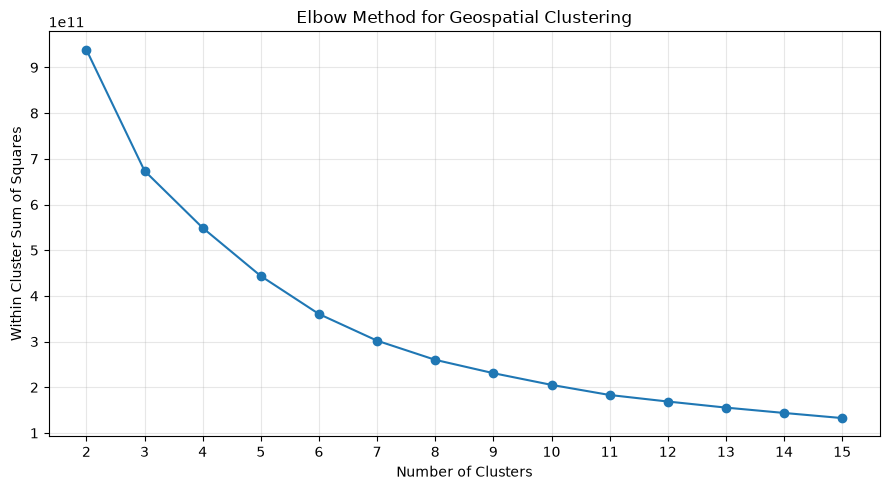

In [73]:
# Evaluate different numbers of clusters using the Elbow method

k_values = range(2, 16)
inertia_values = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_sample)
    inertia_values.append(model.inertia_)

plt.figure(figsize=(9, 5))

plt.plot(
    list(k_values),
    inertia_values,
    marker="o"
)

plt.title("Elbow Method for Geospatial Clustering")
plt.xlabel("Number of Clusters")
plt.ylabel("Within Cluster Sum of Squares")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "02_elbow_method.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


k = 2: Silhouette Score = 0.6513
k = 3: Silhouette Score = 0.3926
k = 4: Silhouette Score = 0.3959
k = 5: Silhouette Score = 0.4183
k = 6: Silhouette Score = 0.4402
k = 7: Silhouette Score = 0.4577
k = 8: Silhouette Score = 0.4602
k = 9: Silhouette Score = 0.4043
k = 10: Silhouette Score = 0.4322
k = 11: Silhouette Score = 0.4317
k = 12: Silhouette Score = 0.4316
k = 13: Silhouette Score = 0.4329
k = 14: Silhouette Score = 0.4024
k = 15: Silhouette Score = 0.4058


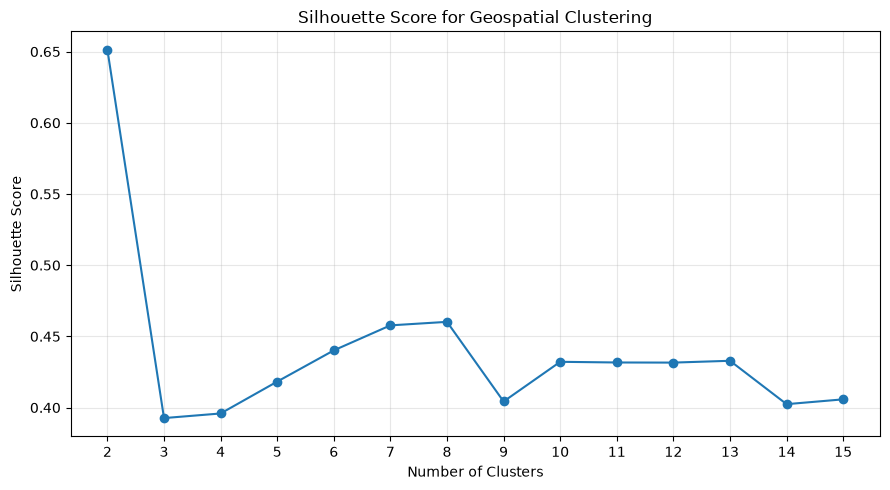


Best number of clusters: 2
Highest Silhouette Score: 0.6513114539567937


In [74]:
from sklearn.metrics import silhouette_score

# Evaluate clustering quality using the Silhouette Score

silhouette_values = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_sample)

    score = silhouette_score(
        X_sample,
        labels,
        sample_size=3000,
        random_state=42
    )

    silhouette_values.append(score)

    print(f"k = {k}: Silhouette Score = {score:.4f}")

plt.figure(figsize=(9, 5))

plt.plot(
    list(k_values),
    silhouette_values,
    marker="o"
)

plt.title("Silhouette Score for Geospatial Clustering")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "02_silhouette_score.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

best_k = list(k_values)[np.argmax(silhouette_values)]

print("\nBest number of clusters:", best_k)
print("Highest Silhouette Score:", max(silhouette_values))


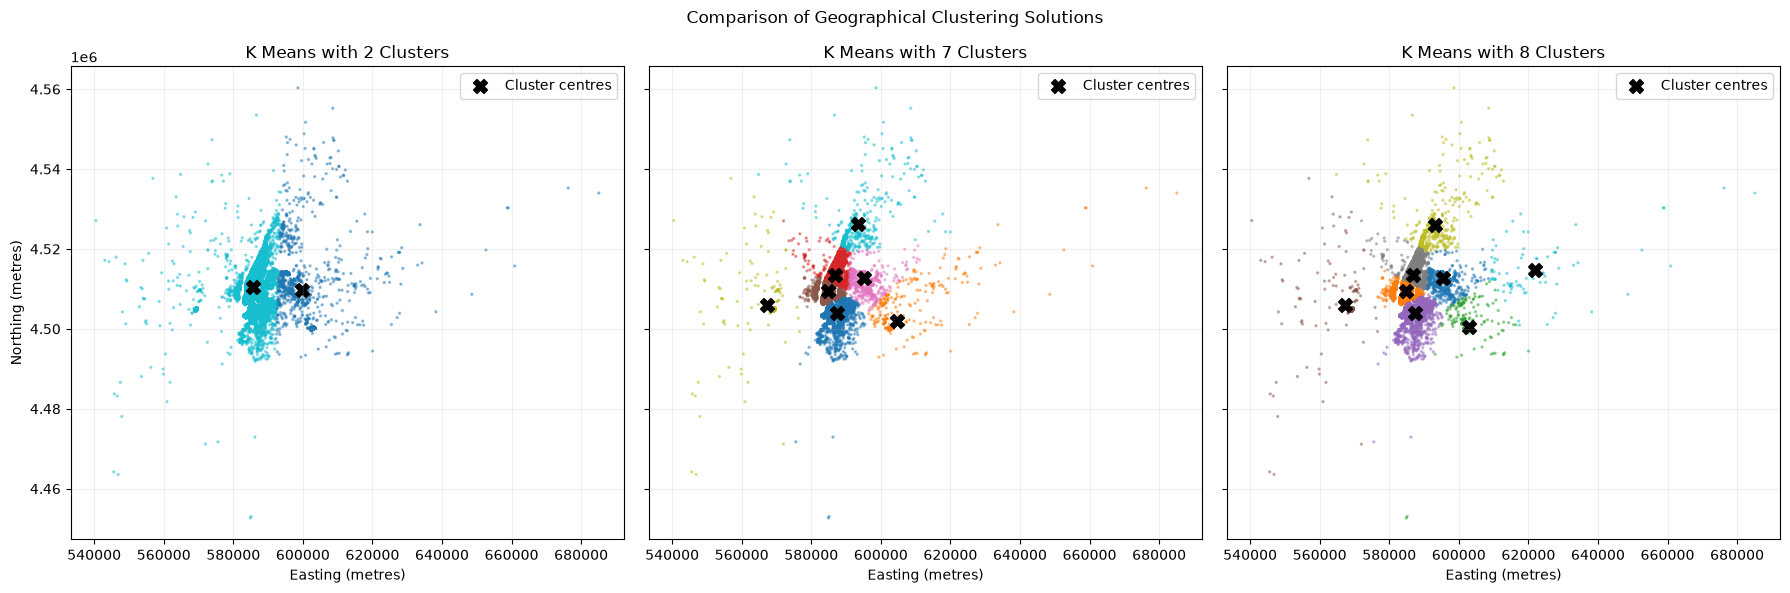

In [75]:
# Compare candidate clustering solutions

candidate_k = [2, 7, 8]

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 6),
    sharex=True,
    sharey=True
)

for ax, k in zip(axes, candidate_k):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_sample)

    ax.scatter(
        X_sample[:, 0],
        X_sample[:, 1],
        c=labels,
        cmap="tab10",
        s=2,
        alpha=0.4
    )

    ax.scatter(
        model.cluster_centers_[:, 0],
        model.cluster_centers_[:, 1],
        c="black",
        marker="X",
        s=100,
        label="Cluster centres"
    )

    ax.set_title(f"K Means with {k} Clusters")
    ax.set_xlabel("Easting (metres)")
    ax.grid(alpha=0.2)
    ax.legend()

axes[0].set_ylabel("Northing (metres)")

plt.suptitle("Comparison of Geographical Clustering Solutions")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "02_kmeans_initial_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [76]:
# Compare cluster sizes for each candidate solution

for k in candidate_k:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_sample)

    cluster_sizes = pd.Series(labels).value_counts().sort_index()

    cluster_summary = pd.DataFrame({
        "Cluster": cluster_sizes.index,
        "Observations": cluster_sizes.values,
        "Percentage": (cluster_sizes.values / len(X_sample) * 100).round(2)
    })

    print(f"\nCLUSTER DISTRIBUTION FOR k = {k}")
    display(cluster_summary)



CLUSTER DISTRIBUTION FOR k = 2


,Cluster,Observations,Percentage
0,0,2199,7.33
1,1,27801,92.67



CLUSTER DISTRIBUTION FOR k = 7


,Cluster,Observations,Percentage
0,0,3488,11.63
1,1,886,2.95
2,2,10355,34.52
3,3,13141,43.80
4,4,1296,4.32
5,5,325,1.08
6,6,509,1.70



CLUSTER DISTRIBUTION FOR k = 8


,Cluster,Observations,Percentage
0,0,1259,4.20
1,1,13098,43.66
2,2,805,2.68
3,3,3603,12.01
4,4,325,1.08
5,5,10314,34.38
6,6,510,1.70
7,7,86,0.29


k = 2: Gap = 3.8011
k = 3: Gap = 3.7885
k = 4: Gap = 3.6111
k = 5: Gap = 3.6008
k = 6: Gap = 3.5898
k = 7: Gap = 3.6432
k = 8: Gap = 3.6632
k = 9: Gap = 3.6585
k = 10: Gap = 3.6605
k = 11: Gap = 3.6594
k = 12: Gap = 3.6444
k = 13: Gap = 3.6563
k = 14: Gap = 3.6683
k = 15: Gap = 3.6833


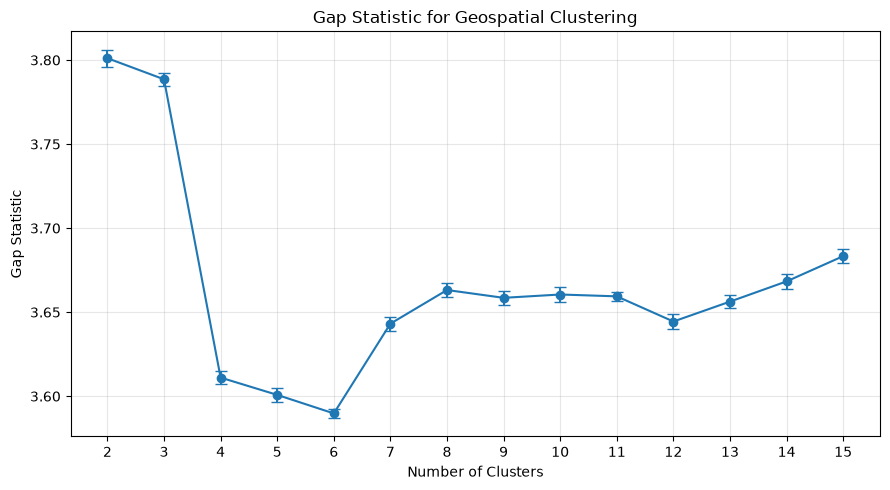

In [77]:
# Calculate the Gap Statistic

from sklearn.cluster import KMeans

rng = np.random.default_rng(42)

k_values_gap = range(2, 16)
n_reference = 10

reference_min = X_sample.min(axis=0)
reference_max = X_sample.max(axis=0)

gap_values = []
gap_standard_errors = []

for k in k_values_gap:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_sample)

    observed_log_dispersion = np.log(model.inertia_)

    reference_log_dispersions = []

    for _ in range(n_reference):
        reference_data = rng.uniform(
            low=reference_min,
            high=reference_max,
            size=X_sample.shape
        )

        reference_model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )
        reference_model.fit(reference_data)

        reference_log_dispersions.append(
            np.log(reference_model.inertia_)
        )

    reference_log_dispersions = np.array(
        reference_log_dispersions
    )

    gap = (
        reference_log_dispersions.mean()
        - observed_log_dispersion
    )

    standard_error = (
        reference_log_dispersions.std(ddof=1)
        * np.sqrt(1 + 1 / n_reference)
    )

    gap_values.append(gap)
    gap_standard_errors.append(standard_error)

    print(f"k = {k}: Gap = {gap:.4f}")

plt.figure(figsize=(9, 5))

plt.errorbar(
    list(k_values_gap),
    gap_values,
    yerr=gap_standard_errors,
    marker="o",
    capsize=4
)

plt.title("Gap Statistic for Geospatial Clustering")
plt.xlabel("Number of Clusters")
plt.ylabel("Gap Statistic")
plt.xticks(list(k_values_gap))
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "02_gap_statistic.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [78]:
# Select the number of clusters using the Gap Statistic rule

gap_results = pd.DataFrame({
    "k": list(k_values_gap),
    "Gap": gap_values,
    "Standard Error": gap_standard_errors
})

display(gap_results.round(4))

optimal_gap_k = None

for i in range(len(gap_values) - 1):
    if gap_values[i] >= (
        gap_values[i + 1] - gap_standard_errors[i + 1]
    ):
        optimal_gap_k = list(k_values_gap)[i]
        break

print("Optimal k according to the Gap Statistic rule:", optimal_gap_k)
gap_results.to_csv(
    RESULTS_DIR / "02_gap_statistic_results.csv",
    index=False
)


,k,Gap,Standard Error
0,2,3.8011,0.0050
1,3,3.7885,0.0039
2,4,3.6111,0.0039
3,5,3.6008,0.0040
4,6,3.5898,0.0028
5,7,3.6432,0.0041
6,8,3.6632,0.0041
7,9,3.6585,0.0042
8,10,3.6605,0.0045
9,11,3.6594,0.0027


Optimal k according to the Gap Statistic rule: 2


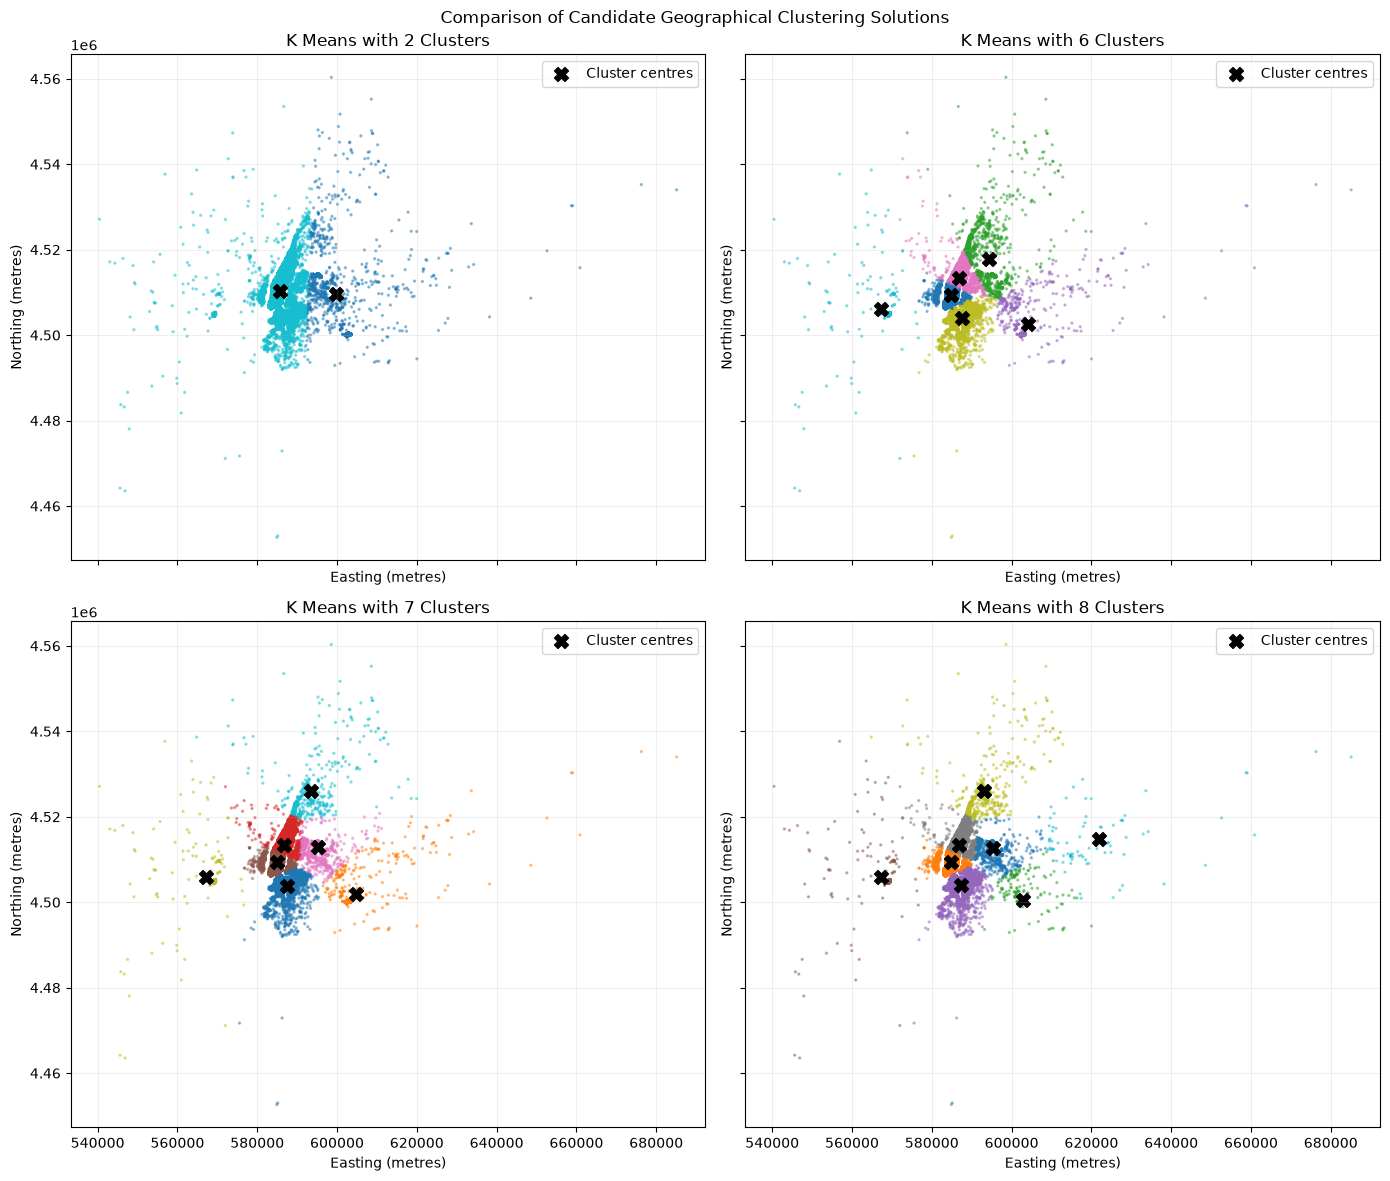

In [79]:
# Compare clustering solutions suggested by validation methods

candidate_k = [2, 6, 7, 8]

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 12),
    sharex=True,
    sharey=True
)

for ax, k in zip(axes.flat, candidate_k):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_sample)

    ax.scatter(
        X_sample[:, 0],
        X_sample[:, 1],
        c=labels,
        cmap="tab10",
        s=2,
        alpha=0.4
    )

    ax.scatter(
        model.cluster_centers_[:, 0],
        model.cluster_centers_[:, 1],
        c="black",
        marker="X",
        s=100,
        label="Cluster centres"
    )

    ax.set_title(f"K Means with {k} Clusters")
    ax.set_xlabel("Easting (metres)")
    ax.set_ylabel("Northing (metres)")
    ax.grid(alpha=0.2)
    ax.legend()

plt.suptitle(
    "Comparison of Candidate Geographical Clustering Solutions"
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "02_kmeans_validation_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

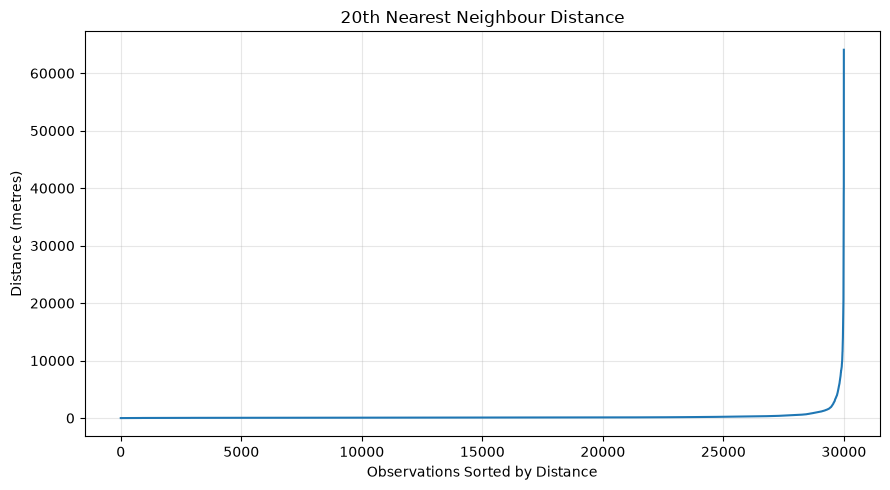

DISTANCE QUANTILES
50%: 83.67 metres
75%: 142.53 metres
90%: 353.85 metres
95%: 708.74 metres
99%: 3871.16 metres


In [80]:
from sklearn.neighbors import NearestNeighbors

# Examine nearest neighbour distances for DBSCAN

min_samples = 20

neighbors = NearestNeighbors(
    n_neighbors=min_samples,
    algorithm="ball_tree"
)

neighbors.fit(X_sample)

distances, _ = neighbors.kneighbors(X_sample)

k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(9, 5))

plt.plot(k_distances)

plt.title("20th Nearest Neighbour Distance")
plt.xlabel("Observations Sorted by Distance")
plt.ylabel("Distance (metres)")
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "02_nearest_neighbour_distances.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("DISTANCE QUANTILES")

for q in [0.50, 0.75, 0.90, 0.95, 0.99]:
    print(
        f"{q:.0%}: {np.quantile(k_distances, q):.2f} metres"
    )


NEAREST NEIGHBOUR DISTANCE QUANTILES
50%: 83.67 metres
75%: 142.53 metres
90%: 353.85 metres
95%: 708.74 metres
97%: 1198.65 metres
99%: 3871.16 metres


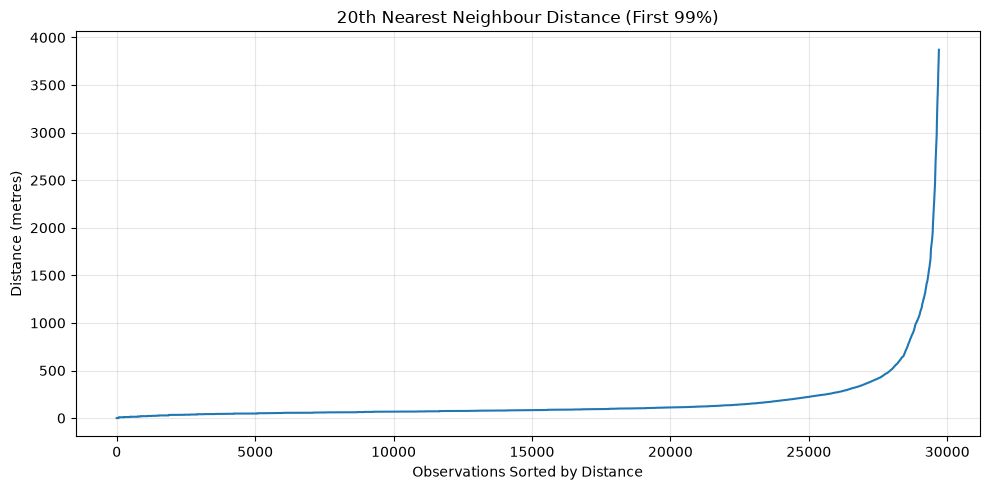

In [81]:
# Examine nearest neighbour distances in greater detail

quantiles = [0.50, 0.75, 0.90, 0.95, 0.97, 0.99]

print("NEAREST NEIGHBOUR DISTANCE QUANTILES")

for q in quantiles:
    distance = np.quantile(k_distances, q)
    print(f"{q:.0%}: {distance:.2f} metres")

# Focus on the first 99% of sorted distances

limit = int(len(k_distances) * 0.99)

plt.figure(figsize=(10, 5))

plt.plot(
    np.arange(limit),
    k_distances[:limit]
)

plt.title("20th Nearest Neighbour Distance (First 99%)")
plt.xlabel("Observations Sorted by Distance")
plt.ylabel("Distance (metres)")
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "02_nearest_neighbour_distances_detail.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [82]:
from sklearn.cluster import DBSCAN

# Compare DBSCAN configurations

eps_values = [150, 350, 700]
dbscan_results = []

for eps in eps_values:
    model = DBSCAN(
        eps=eps,
        min_samples=20,
        algorithm="ball_tree"
    )

    labels = model.fit_predict(X_sample)

    n_clusters = len(set(labels) - {-1})
    n_noise = np.sum(labels == -1)
    noise_percentage = n_noise / len(labels) * 100

    dbscan_results.append({
        "eps (m)": eps,
        "Clusters": n_clusters,
        "Noise (%)": round(noise_percentage, 2)
    })

results_df = pd.DataFrame(dbscan_results)

display(results_df)


,eps (m),Clusters,Noise (%)
0,150,32,20.01
1,350,25,7.62
2,700,10,4.19


In [83]:
# Examine cluster sizes for each DBSCAN configuration

for eps in eps_values:
    model = DBSCAN(
        eps=eps,
        min_samples=20,
        algorithm="ball_tree"
    )

    labels = model.fit_predict(X_sample)

    cluster_distribution = (
        pd.Series(labels, name="Cluster")
        .value_counts()
        .sort_index()
        .reset_index()
    )

    cluster_distribution.columns = [
        "Cluster",
        "Observations"
    ]

    cluster_distribution["Percentage"] = (
        cluster_distribution["Observations"]
        / len(labels) * 100
    ).round(2)

    print(f"\nDBSCAN CLUSTER DISTRIBUTION: eps = {eps} m")

    display(
        cluster_distribution.sort_values(
            "Observations",
            ascending=False
        ).head(12)
    )



DBSCAN CLUSTER DISTRIBUTION: eps = 150 m


,Cluster,Observations,Percentage
1,0,21042,70.14
0,-1,6002,20.01
4,3,690,2.30
3,2,295,0.98
6,5,276,0.92
2,1,265,0.88
11,10,123,0.41
15,14,109,0.36
22,21,98,0.33
18,17,95,0.32



DBSCAN CLUSTER DISTRIBUTION: eps = 350 m


,Cluster,Observations,Percentage
1,0,21748,72.49
0,-1,2286,7.62
6,5,1924,6.41
5,4,1632,5.44
2,1,656,2.19
4,3,300,1.00
8,7,286,0.95
9,8,215,0.72
3,2,207,0.69
7,6,106,0.35



DBSCAN CLUSTER DISTRIBUTION: eps = 700 m


,Cluster,Observations,Percentage
1,0,26703,89.01
0,-1,1256,4.19
2,1,661,2.20
3,2,661,2.20
5,4,229,0.76
4,3,218,0.73
7,6,95,0.32
10,9,56,0.19
9,8,47,0.16
6,5,38,0.13


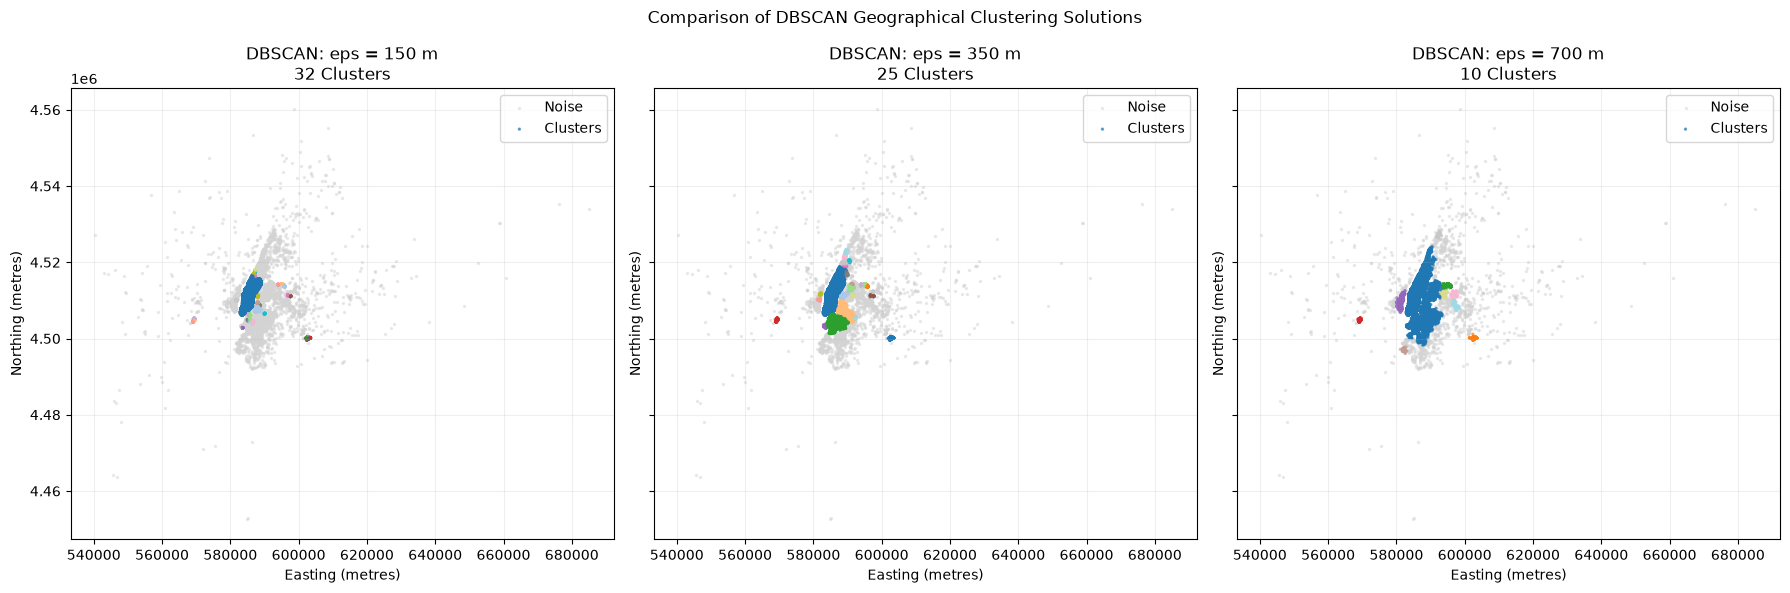

In [84]:
# Visual comparison of DBSCAN configurations

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 6),
    sharex=True,
    sharey=True
)

for ax, eps in zip(axes, eps_values):
    model = DBSCAN(
        eps=eps,
        min_samples=20,
        algorithm="ball_tree"
    )

    labels = model.fit_predict(X_sample)

    noise_mask = labels == -1
    cluster_mask = ~noise_mask

    ax.scatter(
        X_sample[noise_mask, 0],
        X_sample[noise_mask, 1],
        c="lightgray",
        s=2,
        alpha=0.4,
        label="Noise"
    )

    ax.scatter(
        X_sample[cluster_mask, 0],
        X_sample[cluster_mask, 1],
        c=labels[cluster_mask],
        cmap="tab20",
        s=2,
        alpha=0.6,
        label="Clusters"
    )

    n_clusters = len(set(labels) - {-1})

    ax.set_title(
        f"DBSCAN: eps = {eps} m\n"
        f"{n_clusters} Clusters"
    )

    ax.set_xlabel("Easting (metres)")
    ax.set_ylabel("Northing (metres)")
    ax.grid(alpha=0.2)
    ax.legend(loc="upper right")

plt.suptitle(
    "Comparison of DBSCAN Geographical Clustering Solutions"
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "02_dbscan_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [85]:
# DBSCAN summary based on calculated results

dbscan_summary = results_df.copy()

display(dbscan_summary)

dbscan_summary.to_csv(
    "../results/dbscan_summary.csv",
    index=False
)

,eps (m),Clusters,Noise (%)
0,150,32,20.01
1,350,25,7.62
2,700,10,4.19


In [86]:
# Fit the selected K-Means model on the complete dataset

k_selected = 7

final_model = KMeans(
    n_clusters=k_selected,
    random_state=42,
    n_init=10
)

df["Cluster"] = final_model.fit_predict(X)

# Save the classified dataset
df.to_csv(
    "../results/uber_with_clusters.csv",
    index=False
)

print("TOTAL OBSERVATIONS:", len(df))
print("\nCLUSTER DISTRIBUTION")
display(df["Cluster"].value_counts().sort_index())

TOTAL OBSERVATIONS: 1028136

CLUSTER DISTRIBUTION


Cluster
0    358048
1     17651
2    452646
3     30983
4     44026
5     10198
6    114584
Name: count, dtype: int64